In [1]:
import math
import matplotlib.pyplot as plt
import pandas as pd


def plot_csv_columns(file_path):
  """Reads a CSV file and plots each numeric column in a single figure

  using subplots.
  """
  # 1. Load the CSV file
  df = pd.read_csv(file_path)

  # 2. Filter for numeric columns (skip text/categorical columns)
  numeric_cols = df.select_dtypes(include="number").columns
  num_cols = len(numeric_cols)

  if num_cols == 0:
    print("No numeric columns found in the CSV to plot.")
    return

  # 3. Determine grid dimensions (max 3 subplots per row)
  ncols = 4 if num_cols >= 4 else num_cols
  nrows = math.ceil(num_cols / ncols)

  # 4. Create the figure and subplots grid
  # squeeze=False ensures 'axes' is always a 2D array for easy iteration
  fig, axes = plt.subplots(
      nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4 * nrows), 
  )
  axes_flat = axes.flatten()

  # 5. Plot each column
  for i, col in enumerate(numeric_cols):
    ax = axes_flat[i]
    ax.plot(df[col], marker="o", linestyle="-", markersize=3, color="tab:blue")
    ax.set_title(f"{col}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Index", fontsize=9)
    ax.set_ylabel("Value", fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.5)

  # 6. Hide any unused subplots in the grid
  for j in range(i + 1, len(axes_flat)):
    fig.delaxes(axes_flat[j])

  # 7. Adjust layout and display
  plt.suptitle(
      f"Overview of Columns in: {file_path}",
      fontsize=14,
      fontweight="bold",
      y=1.02,
  )
  plt.tight_layout()
  plt.show()


# Example usage:
# plot_csv_columns('path/to/your/data.csv')

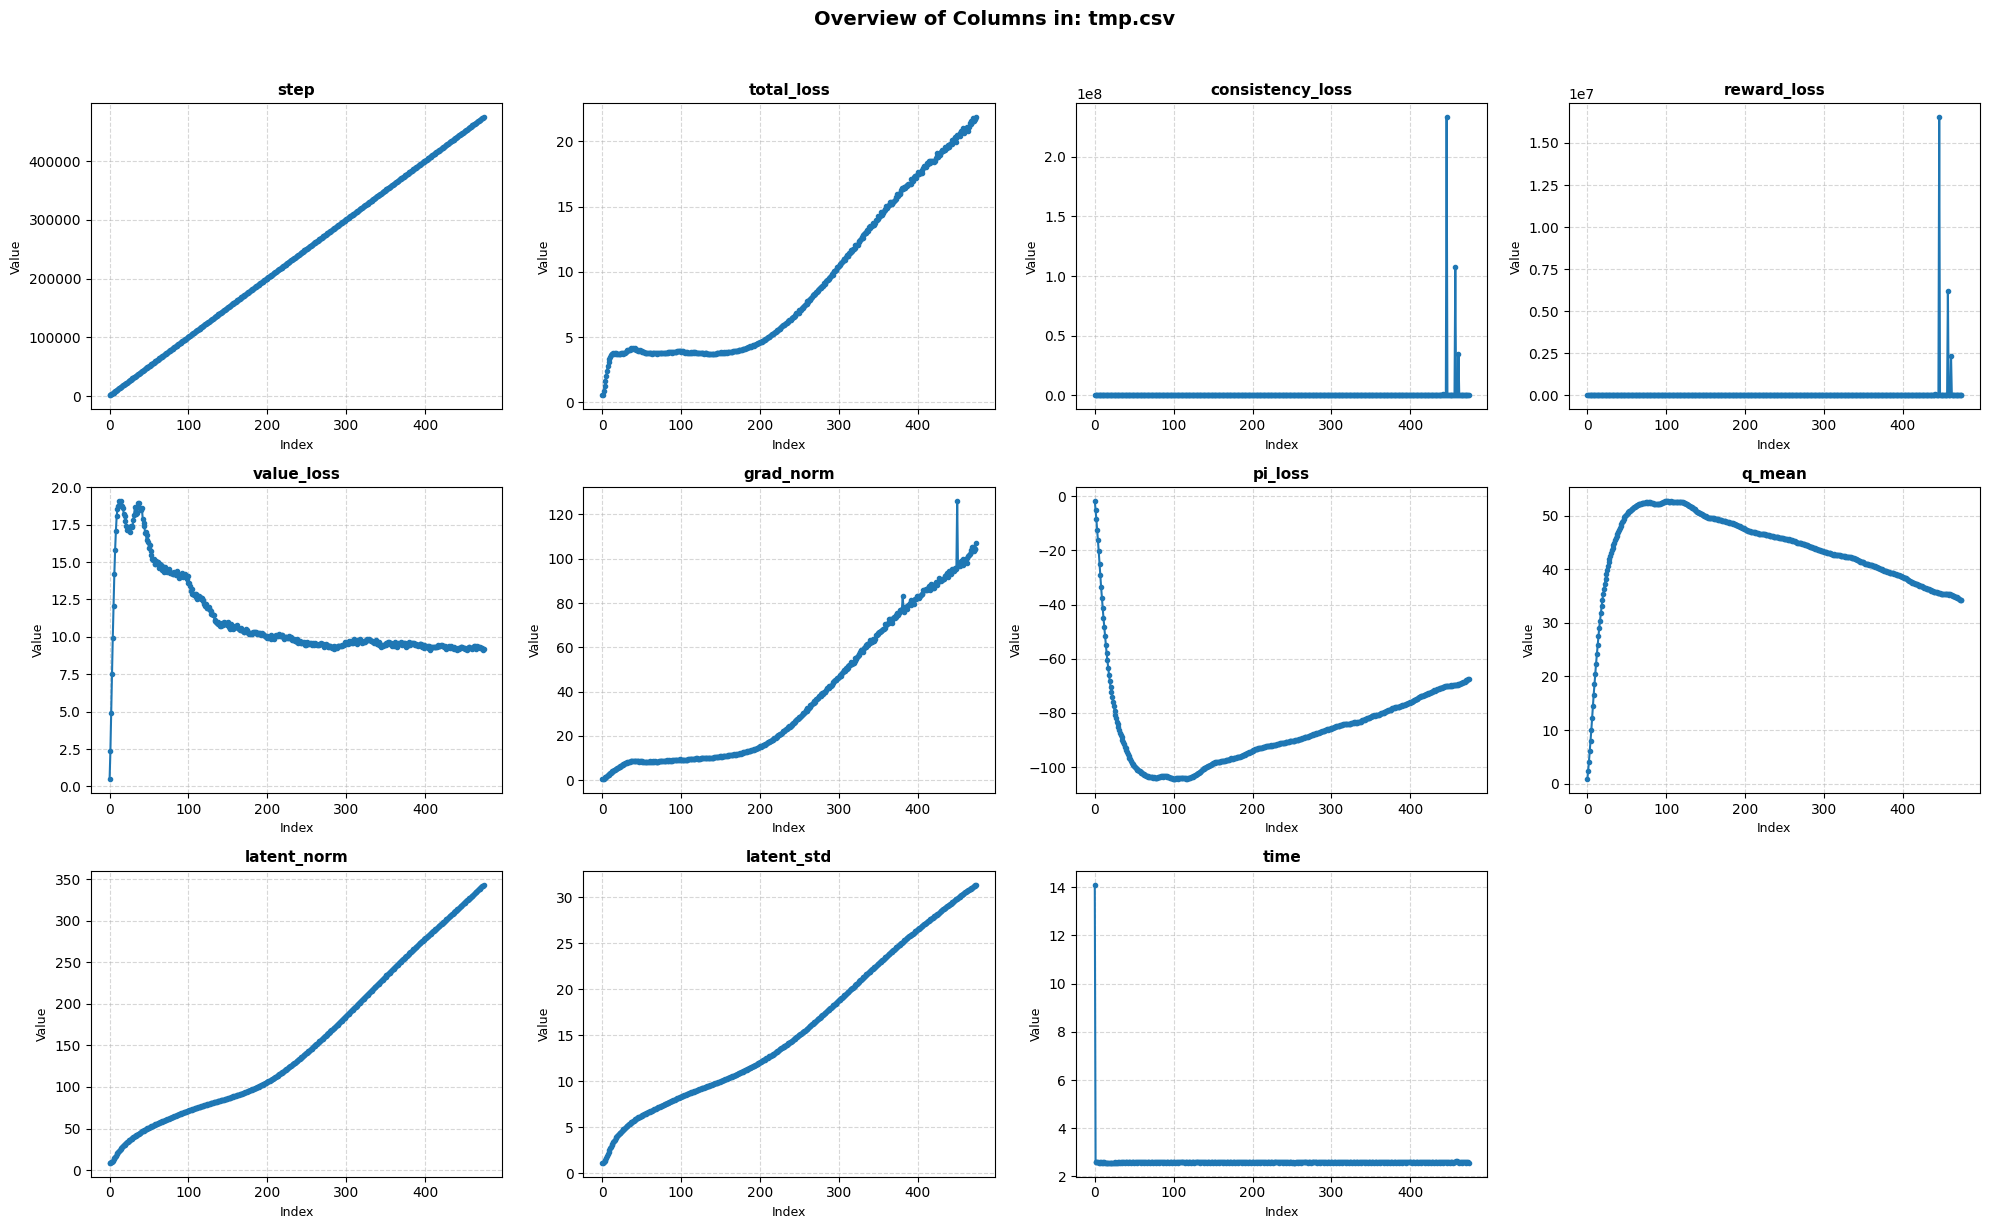

In [22]:
path = """



tmp.csv

""".strip()

plot_csv_columns(path)

In [7]:
from dm_control import suite

In [3]:
env = suite.load(domain_name='cheetah', task_name='run', environment_kwargs=dict(flat_observation=True))